# Exploratory Analysis — UCI Cleveland Heart Disease Data

**Author:** Surbhi Arya (BITS ID: 2025AE05688)
**Course:** AIMLCZG523 — MLOps, Assignment 1

Goal: understand the dataset well enough to justify the feature
engineering decisions in `heart_risk/transform.py` before touching any
models. The two models trained later (Decision Tree, Gradient Boosting)
are both tree-based, which shapes a few choices below (e.g. not
one-hot-encoding the categorical columns).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

frame = pd.read_csv("../data/raw/heart_disease.csv")
frame.shape


(303, 14)

## 1. Shape and dtypes

In [2]:
frame.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
frame.dtypes.to_frame("dtype")

,dtype
age,float64
sex,float64
cp,float64
trestbps,float64
chol,float64
fbs,float64
restecg,float64
thalach,float64
exang,float64
oldpeak,float64


Column reference (the raw UCI names aren't self-explanatory):

- `age`, `sex` (1=male), `cp` (chest pain type, 1-4)
- `trestbps` (resting BP), `chol` (cholesterol), `fbs` (fasting blood sugar > 120, 0/1)
- `restecg` (resting ECG, 0-2), `thalach` (max heart rate), `exang` (exercise angina, 0/1)
- `oldpeak` (ST depression), `slope` (ST slope, 1-3)
- `ca` (# major vessels, 0-3), `thal` (3=normal, 6=fixed defect, 7=reversible defect)
- `target` (0=no disease, 1=disease) — derived from the original 0-4 severity score


## 2. Missing data

In [4]:
missing = frame.isna().sum()
missing[missing > 0].to_frame("missing_count")


,missing_count
ca,4
thal,2


Just 6 cells across the whole dataset (`ca`: 4, `thal`: 2) — small
enough that the imputation method barely matters for overall model
quality, but I'm using `KNNImputer` for the continuous columns anyway
(see `transform.py`) rather than a plain median, mostly because it's a
near-zero-cost upgrade at this data size.

## 3. Target balance

/var/folders/hc/s5z1cqk17b32rhvhcfd3rcx80000gp/T/ipykernel_40166/1331689807.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, ax=ax, palette="deep")


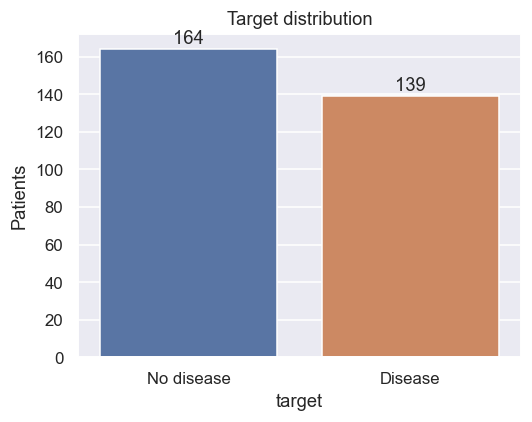

target
0    0.541
1    0.459
Name: proportion, dtype: float64

In [5]:
counts = frame["target"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 4))
sns.barplot(x=counts.index, y=counts.values, ax=ax, palette="deep")
ax.set_xticks([0, 1])
ax.set_xticklabels(["No disease", "Disease"])
ax.set_ylabel("Patients")
ax.set_title("Target distribution")
for i, v in enumerate(counts.values):
    ax.text(i, v + 3, str(v), ha="center")
plt.tight_layout()
plt.savefig("../docs/figures/target_distribution.png")
plt.show()

frame["target"].value_counts(normalize=True).round(3)


46% positive rate — mild imbalance, not severe enough to need resampling. Stratified splitting is used everywhere downstream regardless, since 303 rows is a small sample to begin with.

## 4. Continuous feature distributions, split by target

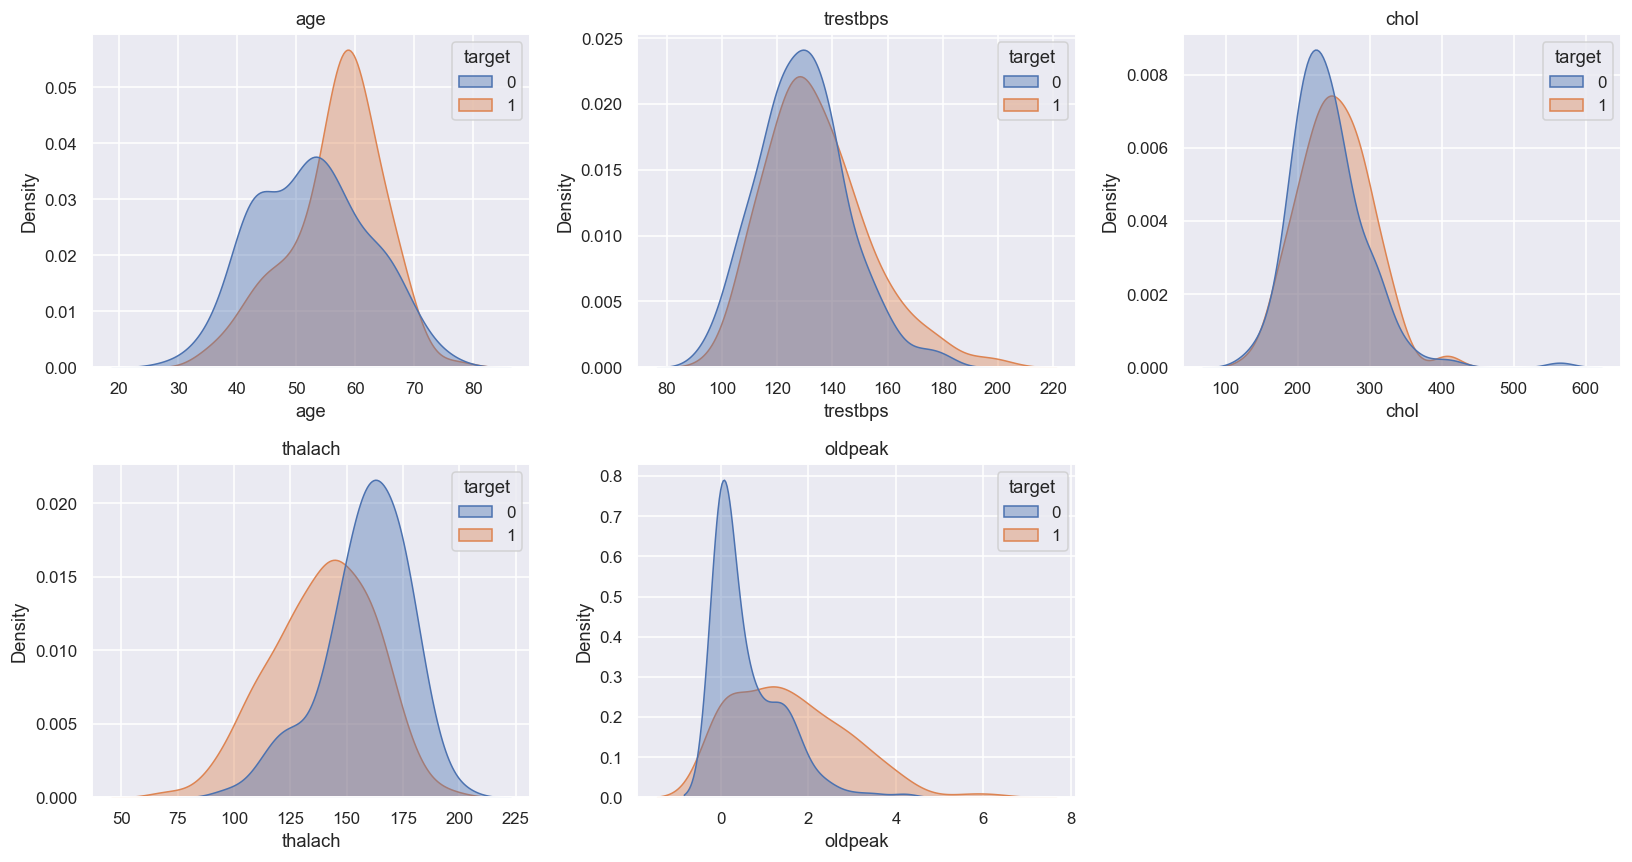

In [6]:
continuous_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for ax, col in zip(axes, continuous_cols):
    sns.kdeplot(data=frame, x=col, hue="target", fill=True, common_norm=False, ax=ax, alpha=0.4)
    ax.set_title(col)
axes[-1].axis("off")
plt.tight_layout()
plt.savefig("../docs/figures/continuous_kde_by_target.png")
plt.show()


The clearest separations: **thalach** (max heart rate) shifts lower
for the disease group, **oldpeak** shifts higher. Both track with reduced
cardiovascular capacity under stress. `chol` and `trestbps` show heavy
overlap between classes — on their own they're weak predictors, which is
part of the motivation for leaning on a model that can combine many
features (gradient boosting) rather than expecting any single variable to
do the work.

## 5. Categorical features vs. target

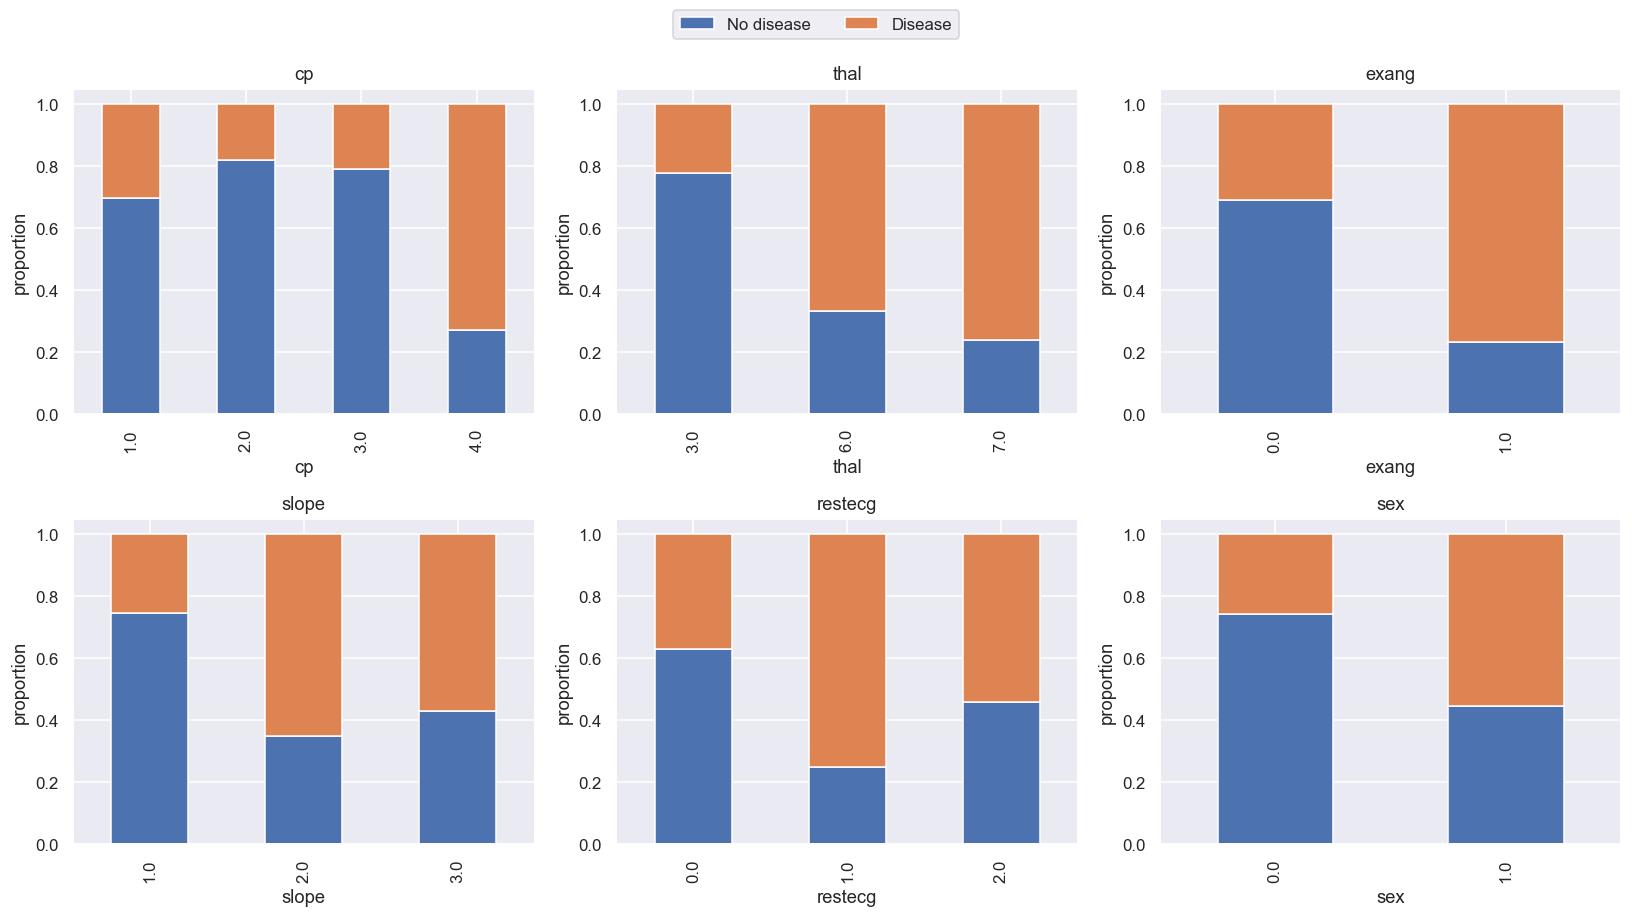

In [7]:
cat_cols = ["cp", "thal", "exang", "slope", "restecg", "sex"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for ax, col in zip(axes, cat_cols):
    ct = pd.crosstab(frame[col], frame["target"], normalize="index")
    ct.plot(kind="bar", stacked=True, ax=ax, color=["#4C72B0", "#DD8452"], legend=False)
    ax.set_title(col)
    ax.set_ylabel("proportion")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, ["No disease", "Disease"], loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.05))
plt.tight_layout()
plt.savefig("../docs/figures/categorical_proportions_by_target.png", bbox_inches="tight")
plt.show()


`thal` and `cp` are the standouts — certain categories are almost
entirely one class (e.g. `thal=3` skews heavily "no disease", `thal=7`
skews heavily "disease"). This is exactly the kind of signal a decision
tree can exploit directly from an ordinal-encoded integer, without
needing one-hot expansion.

## 6. Correlation structure

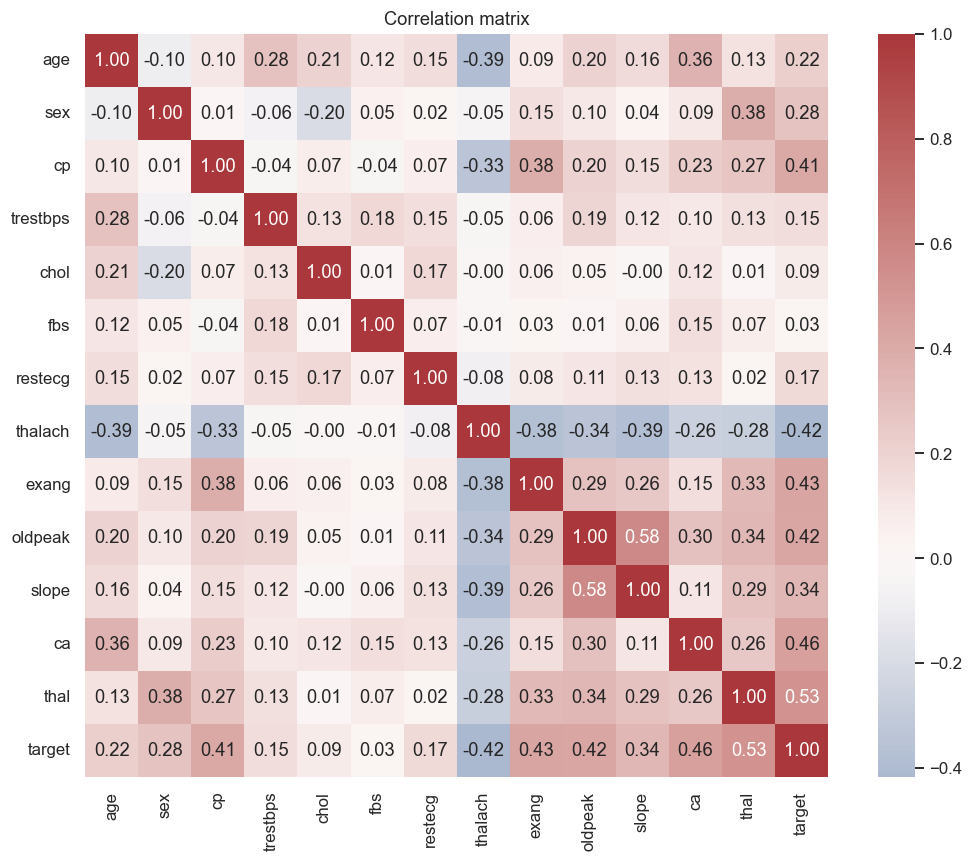

In [8]:
corr = frame.corr(numeric_only=True)
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True)
plt.title("Correlation matrix")
plt.tight_layout()
plt.savefig("../docs/figures/correlation_matrix.png")
plt.show()


No pair of predictors is alarmingly collinear (nothing above ~0.6 in absolute value), so nothing was dropped for redundancy.

## 7. Feature engineering decisions carried into `transform.py`

- **KNNImputer (k=5)** for continuous columns — small upgrade over median imputation given so few missing cells.
- **Ordinal encoding** (not one-hot) for `cp`, `restecg`, `slope`, `thal`, `ca` — appropriate given both downstream models are tree-based, and keeps the feature space compact on a 303-row dataset.
- **Derived `age_group`** (young / middle / senior) added as an extra engineered column, motivated by the visibly different `thalach`/`oldpeak` behavior across age ranges seen above.
- **No features dropped** — correlation analysis didn't justify removing anything.
- **No resampling** — 46/54 class split is close enough to balanced.
